In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [5]:
import os

print(os.listdir("/kaggle/input"))

['datasets']


In [6]:
import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch: 2.11.0+cpu
GPU available: False


In [1]:
import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [3]:
import os

dataset_path = "/kaggle/input/datasets"

print("Folders and files inside dataset:")
print(os.listdir(dataset_path))

Folders and files inside dataset:
['prithivsakthiur']


In [4]:
import os

dataset_path = "/kaggle/input/datasets/prithivsakthiur"

print(os.listdir(dataset_path))

['deepfake-vs-real-60k']


In [9]:
import os

dataset_path = "/kaggle/input/datasets/prithivsakthiur/deepfake-vs-real-60k"

print("Dataset exists:", os.path.exists(dataset_path))
print("\nMain folders and files:")

for item in os.listdir(dataset_path):
    full_path = os.path.join(dataset_path, item)

    if os.path.isdir(full_path):
        print("📁", item)
    else:
        print("📄", item)

Dataset exists: True

Main folders and files:
📁 deepfake-vs-real-60k


In [10]:
import os

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    # Show only the first 3 folder levels
    if level <= 3:
        indent = "    " * level
        print(f"{indent}📁 {os.path.basename(root)}/")

        for file in files[:5]:
            print(f"{indent}    📄 {file}")

        if len(files) > 5:
            print(f"{indent}    ... and {len(files) - 5} more files")

📁 deepfake-vs-real-60k/
    📁 deepfake-vs-real-60k/
        📁 Fake/
            📄 0001 (1).jpg
            📄 0001 (10).jpg
            📄 0001 (100).jpg
            📄 0001 (1000).jpg
            📄 0001 (10000).jpg
            ... and 28591 more files
        📁 Real/
            📄 0001 (1).png
            📄 0001 (10).png
            📄 0001 (100).png
            📄 0001 (1000).png
            📄 0001 (10000).png
            ... and 28470 more files


In [11]:
import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [12]:
import os

dataset_path = "/kaggle/input/datasets/prithivsakthiur/deepfake-vs-real-60k"

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level <= 3:
        indent = "    " * level
        print(f"{indent}{os.path.basename(root)}/")

        for file in files[:5]:
            print(f"{indent}    {file}")

deepfake-vs-real-60k/
    deepfake-vs-real-60k/
        Fake/
            0001 (1).jpg
            0001 (10).jpg
            0001 (100).jpg
            0001 (1000).jpg
            0001 (10000).jpg
        Real/
            0001 (1).png
            0001 (10).png
            0001 (100).png
            0001 (1000).png
            0001 (10000).png


In [13]:
import os

DATASET_PATH = "/kaggle/input/datasets/prithivsakthiur/deepfake-vs-real-60k/deepfake-vs-real-60k"

FAKE_PATH = os.path.join(DATASET_PATH, "Fake")
REAL_PATH = os.path.join(DATASET_PATH, "Real")

print("Dataset exists:", os.path.exists(DATASET_PATH))
print("Fake folder exists:", os.path.exists(FAKE_PATH))
print("Real folder exists:", os.path.exists(REAL_PATH))

Dataset exists: True
Fake folder exists: True
Real folder exists: True


In [14]:
import os

fake_images = [
    f for f in os.listdir(FAKE_PATH)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

real_images = [
    f for f in os.listdir(REAL_PATH)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Fake images:", len(fake_images))
print("Real images:", len(real_images))
print("Total images:", len(fake_images) + len(real_images))

Fake images: 28596
Real images: 28475
Total images: 57071


In [15]:
from PIL import Image
import os

print("Checking Fake images:")

for filename in fake_images[:3]:
    path = os.path.join(FAKE_PATH, filename)

    try:
        img = Image.open(path)
        print(filename, img.size, img.format)
    except Exception as e:
        print("Error:", filename, e)

print("\nChecking Real images:")

for filename in real_images[:3]:
    path = os.path.join(REAL_PATH, filename)

    try:
        img = Image.open(path)
        print(filename, img.size, img.format)
    except Exception as e:
        print("Error:", filename, e)

Checking Fake images:
0001 (1).jpg (960, 1490) JPEG
0001 (10).jpg (1125, 1585) JPEG
0001 (100).jpg (598, 598) JPEG

Checking Real images:
0001 (1).png (512, 512) PNG
0001 (10).png (512, 512) PNG
0001 (100).png (512, 512) PNG


In [16]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

print("Libraries imported successfully!")
print("GPU:", torch.cuda.get_device_name(0))

Libraries imported successfully!
GPU: Tesla T4


In [17]:
DATASET_PATH = "/kaggle/input/datasets/prithivsakthiur/deepfake-vs-real-60k/deepfake-vs-real-60k"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [18]:
from torchvision.datasets import ImageFolder

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

full_dataset = ImageFolder(
    root=DATASET_PATH,
    transform=transform
)

print("Class names:", full_dataset.classes)
print("Total images available:", len(full_dataset))
print("Class mapping:", full_dataset.class_to_idx)

Class names: ['Fake', 'Real']
Total images available: 57071
Class mapping: {'Fake': 0, 'Real': 1}


In [20]:
from collections import defaultdict

class_indices = defaultdict(list)

for index, (_, label) in enumerate(full_dataset.samples):
    class_indices[label].append(index)

random.seed(42)

selected_indices = []

for label in class_indices:
    selected = random.sample(
        class_indices[label],
        min(500, len(class_indices[label]))
    )
    selected_indices.extend(selected)

random.shuffle(selected_indices)

small_dataset = Subset(full_dataset, selected_indices)

print("Selected images:", len(small_dataset))

Selected images: 1000


In [21]:
labels = [
    full_dataset.samples[i][1]
    for i in selected_indices
]

train_idx, temp_idx = train_test_split(
    selected_indices,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

temp_labels = [
    full_dataset.samples[i][1]
    for i in temp_idx
]

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

train_dataset = Subset(full_dataset, train_idx)
val_dataset = Subset(full_dataset, val_idx)
test_dataset = Subset(full_dataset, test_idx)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

Training images: 800
Validation images: 100
Testing images: 100


In [22]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders ready!")

DataLoaders ready!


In [23]:
class DeepfakeCNN(nn.Module):

    def __init__(self):
        super(DeepfakeCNN, self).__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = DeepfakeCNN().to(device)

print(model)

DeepfakeCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32768, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)


In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 5

In [34]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 5

In [35]:
for epoch in range(EPOCHS):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Loss: {running_loss/len(train_loader):.4f} "
        f"Accuracy: {train_accuracy:.2f}%"
    )

Epoch [1/5] Loss: 0.5279 Accuracy: 73.50%
Epoch [2/5] Loss: 0.2423 Accuracy: 90.38%
Epoch [3/5] Loss: 0.1386 Accuracy: 95.12%
Epoch [4/5] Loss: 0.0559 Accuracy: 98.00%
Epoch [5/5] Loss: 0.0316 Accuracy: 98.88%


In [36]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

val_accuracy = 100 * correct / total

print(f"Validation Accuracy: {val_accuracy:.2f}%")

Validation Accuracy: 94.00%


In [37]:
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(
    all_labels,
    all_predictions,
    target_names=full_dataset.classes
))

              precision    recall  f1-score   support

        Fake       1.00      0.96      0.98        50
        Real       0.96      1.00      0.98        50

    accuracy                           0.98       100
   macro avg       0.98      0.98      0.98       100
weighted avg       0.98      0.98      0.98       100



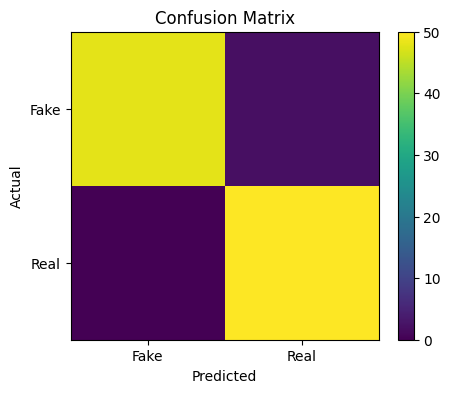

In [38]:
cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], full_dataset.classes)
plt.yticks([0, 1], full_dataset.classes)
plt.colorbar()
plt.show()

In [39]:
torch.save(
    model.state_dict(),
    "/kaggle/working/deepfake_cnn.pth"
)

print("Model saved successfully!")

Model saved successfully!


In [40]:
import torch

model = DeepfakeCNN().to(device)

model.load_state_dict(
    torch.load(
        "/kaggle/working/deepfake_cnn.pth",
        map_location=device
    )
)

model.eval()

print("Trained model loaded successfully!")

Trained model loaded successfully!


Actual: Real
Predicted: Real
Confidence: 98.6 %


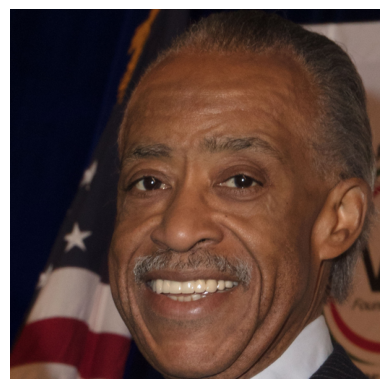

In [41]:
import random
import os
from PIL import Image
import matplotlib.pyplot as plt

# Select a random test image
random_index = random.choice(test_idx)

image_path, actual_label = full_dataset.samples[random_index]

# Load image
image = Image.open(image_path).convert("RGB")

# Apply the same preprocessing
input_tensor = transform(image).unsqueeze(0).to(device)

# Predict
with torch.no_grad():
    output = model(input_tensor)
    probabilities = torch.softmax(output, dim=1)
    predicted_label = torch.argmax(probabilities, dim=1).item()

class_names = full_dataset.classes

print("Actual:", class_names[actual_label])
print("Predicted:", class_names[predicted_label])
print("Confidence:", round(probabilities[0][predicted_label].item() * 100, 2), "%")

plt.imshow(image)
plt.axis("off")
plt.show()

In [47]:
def predict_deepfake(image_path):

    image = Image.open(image_path).convert("RGB")

    input_tensor = transform(image).unsqueeze(0).to(device)

    model.eval()

    with torch.no_grad():
        output = model(input_tensor)
        probabilities = torch.softmax(output, dim=1)

        predicted_label = torch.argmax(
            probabilities, dim=1
        ).item()

    prediction = full_dataset.classes[predicted_label]
    confidence = probabilities[0][predicted_label].item() * 100

    print("Prediction:", prediction)
    print(f"Model confidence: {confidence:.2f}%")

    plt.imshow(image)
    plt.title(f"{prediction} ({confidence:.2f}%)")
    plt.axis("off")
    plt.show()

    return prediction

Prediction: Fake
Model confidence: 98.40%


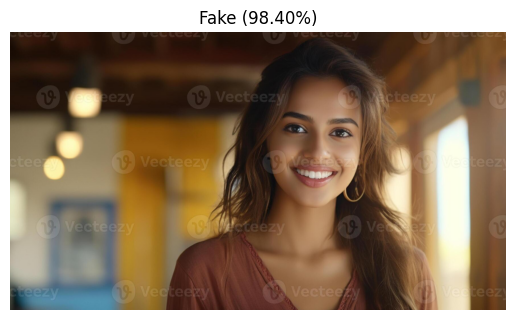

'Fake'

In [50]:
predict_deepfake("/kaggle/input/datasets/ardhraprem/sample/deepfake project.jpg")